In [1]:
import numpy as np
from argparse import Namespace
from solver.kolmogorov_flow import KolmogorovFlow2d
from generate_data import legacy_solver, gen_data
from prepare_data import shuffle_data, test_data, get_slice

In [ ]:
legacy_args = Namespace(
    outdir="./data_sequence",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=100.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=256,     # t축 픽셀 개수
    independent_ic=False,
)

legacy_solver(legacy_args)


  0%|          | 0/40 [00:00<?, ?it/s]

In [ ]:
legacy_args = Namespace(
    outdir="./data",
    re=1000.0,
    res_x=256,
    T=40,             # trajectory 개수
    warmup=100.0,
    seed=0,

    T_phys=10.0,      # 물리 시간 도메인 [0, 10]
    n_frames=256,     # t축 픽셀 개수
    independent_ic=True,
)

legacy_solver(legacy_args)


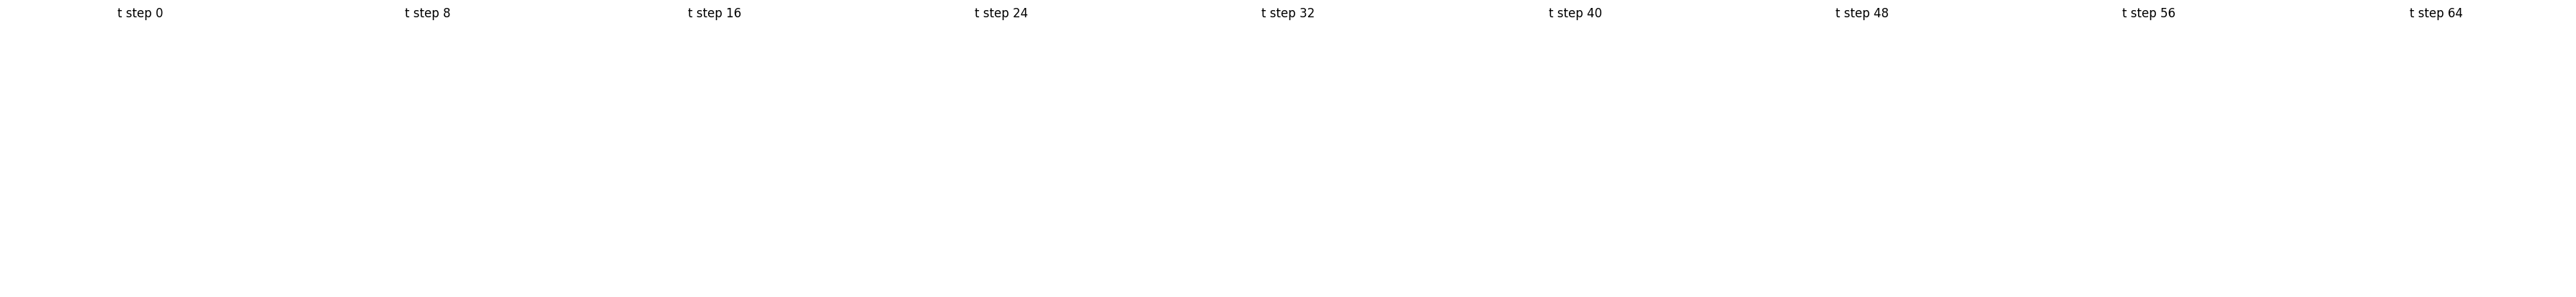

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def plot_kol_sequence(npy_path, window_idx=0, step=1):
    data = np.load(npy_path, mmap_mode='r')
    seq = data[window_idx]   # (t_res+1, H, W)

    ncols = len(range(0, seq.shape[0], step))
    fig, axes = plt.subplots(1, ncols, figsize=(4 * ncols, 4))
    if ncols == 1:
        axes = [axes]

    for ax, t in zip(axes, range(0, seq.shape[0], step)):
        ax.imshow(seq[t], cmap='turbo', origin='lower')
        ax.set_title(f't step {t}')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Example
plot_kol_sequence('./data/NS-Re500_T64.npy', window_idx=3, step=8)


In [ ]:
ns_args = Namespace(
    outdir='./data_ns',
    re=40.0,
    x_res=512,
    x_sub=2,
    T=10,
    t_res=128,
    batchsize=4,
    num_batchs=1,
    seed=0
)
ns_paths = gen_data(ns_args)
print('NS dataset files:', ns_paths)


NameError: name 'ns_args' is not defined